# Exploratory Data Analysis

Explore the Online Retail transactions before customer segmentation. Raw data is kept here to inspect cancellations, returns, and unusual values.

## Setup and data loading

In [23]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="Set2")
df = pd.read_excel(Path("../data/Online Retail.xlsx"))
df.columns = df.columns.str.strip()
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


# Data Overview

Inspect structure, descriptive statistics, ranges, unique values, and missingness.

## Dataset information

In [24]:
print(f"Rows: {len(df):,}; columns: {df.shape[1]}")
print(f"Exact duplicate rows: {df.duplicated().sum():,}")
df.info()

Rows: 541,909; columns: 8
Exact duplicate rows: 5,268
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


## Descriptive statistics

In [25]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Range checks

In [26]:
overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique()
})
ranges = df.select_dtypes(include="number").agg(["min", "max"]).T
ranges.columns = ["minimum", "maximum"]
display(overview.join(ranges))
print("InvoiceDate range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("Rows with Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Rows with UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())
print("Cancellation invoices:", df["InvoiceNo"].astype("string").str.startswith("C", na=False).sum())

,dtype,missing_count,missing_percent,unique_values,minimum,maximum
InvoiceNo,object,0,0.00,25900,NaN,NaN
StockCode,object,0,0.00,4070,NaN,NaN
Description,object,1454,0.27,4223,NaN,NaN
Quantity,int64,0,0.00,722,-80995.00,80995.0
InvoiceDate,datetime64[us],0,0.00,23260,NaN,NaN
UnitPrice,float64,0,0.00,1630,-11062.06,38970.0
CustomerID,float64,135080,24.93,4372,12346.00,18287.0
Country,str,0,0.00,38,NaN,NaN


InvoiceDate range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Rows with Quantity <= 0: 10624
Rows with UnitPrice <= 0: 2517
Cancellation invoices: 9288


## Unique values and missingness

In [27]:
display(pd.DataFrame({
    "unique_values": df.nunique(),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("unique_values", ascending=False))

,unique_values,missing_count,missing_percent
InvoiceNo,25900,0,0.00
InvoiceDate,23260,0,0.00
CustomerID,4372,135080,24.93
Description,4223,1454,0.27
StockCode,4070,0,0.00
UnitPrice,1630,0,0.00
Quantity,722,0,0.00
Country,38,0,0.00


# Distribution Analysis

Categorical variables use percentage value counts and bar charts. Numeric variables use histograms, boxplots, skewness, and Fisher kurtosis. Identifiers are treated as categories, not measurements.

## InvoiceNo

InvoiceNo
573585    0.21
581219    0.14
581492    0.13
580729    0.13
558475    0.13
579777    0.13
581217    0.12
537434    0.12
580730    0.12
538071    0.12
580367    0.12
580115    0.12
581439    0.12
580983    0.12
578344    0.11
538349    0.11
578347    0.11
537638    0.11
537237    0.11
536876    0.11
Name: Percentage (%), dtype: Float64

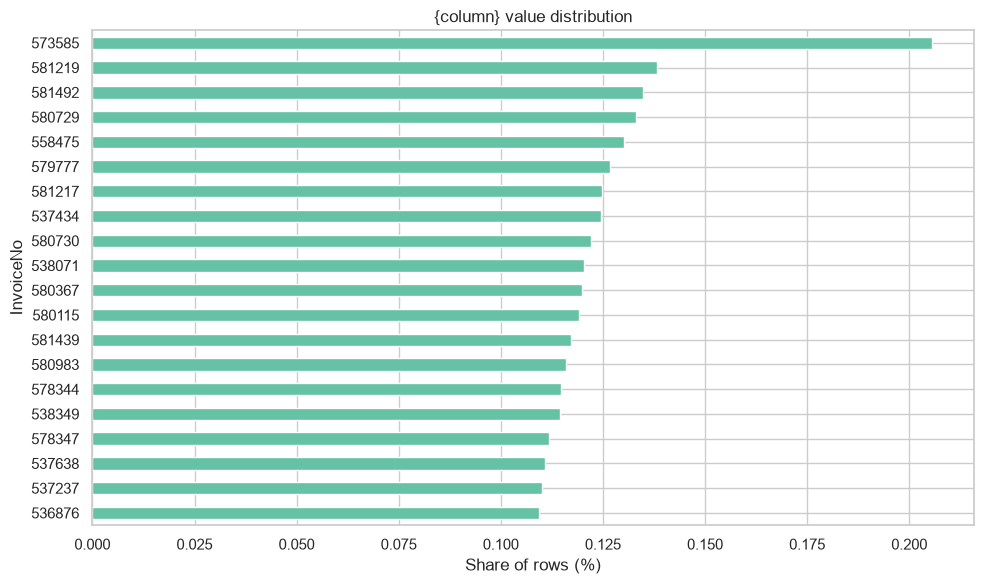

In [28]:
column = "InvoiceNo"
percentages = df[column].astype("string").fillna("Missing").value_counts(normalize=True).mul(100)
display(percentages.head(20).rename("Percentage (%)").round(2))
ax = percentages.head(20).sort_values().plot.barh(figsize=(10, 6))
ax.set(title=f"{{column}} value distribution", xlabel="Share of rows (%)", ylabel=column)
plt.tight_layout()
plt.show()

## StockCode

StockCode
85123A    0.43
22423     0.41
85099B     0.4
47566     0.32
20725      0.3
84879     0.28
22720     0.27
22197     0.27
21212     0.26
20727     0.25
22383     0.25
22457     0.24
23203     0.23
POST      0.23
22386     0.23
22469     0.23
22960     0.23
21931     0.22
22086     0.22
22411     0.22
Name: Percentage (%), dtype: Float64

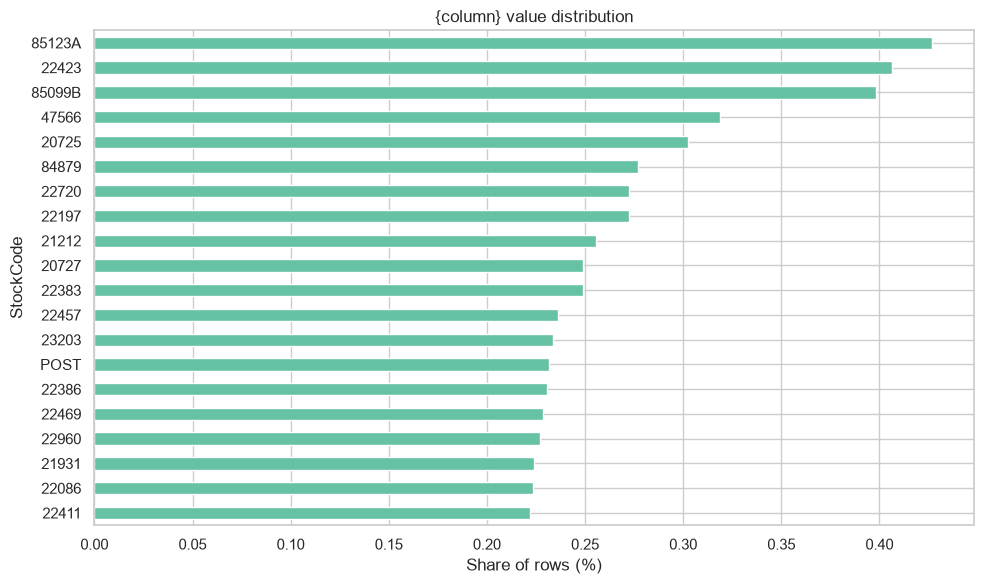

In [29]:
column = "StockCode"
percentages = df[column].astype("string").fillna("Missing").value_counts(normalize=True).mul(100)
display(percentages.head(20).rename("Percentage (%)").round(2))
ax = percentages.head(20).sort_values().plot.barh(figsize=(10, 6))
ax.set(title=f"{{column}} value distribution", xlabel="Share of rows (%)", ylabel=column)
plt.tight_layout()
plt.show()

## Description

Description
WHITE HANGING HEART T-LIGHT HOLDER    0.44
REGENCY CAKESTAND 3 TIER              0.41
JUMBO BAG RED RETROSPOT                0.4
PARTY BUNTING                         0.32
LUNCH BAG RED RETROSPOT                0.3
ASSORTED COLOUR BIRD ORNAMENT         0.28
SET OF 3 CAKE TINS PANTRY DESIGN      0.27
Missing                               0.27
PACK OF 72 RETROSPOT CAKE CASES       0.26
LUNCH BAG  BLACK SKULL.               0.25
NATURAL SLATE HEART CHALKBOARD        0.24
POSTAGE                               0.23
JUMBO BAG PINK POLKADOT               0.23
HEART OF WICKER SMALL                 0.23
JAM MAKING SET WITH JARS              0.23
JUMBO STORAGE BAG SUKI                0.22
PAPER CHAIN KIT 50'S CHRISTMAS        0.22
JUMBO SHOPPER VINTAGE RED PAISLEY     0.22
LUNCH BAG CARS BLUE                   0.22
LUNCH BAG SPACEBOY DESIGN             0.22
Name: Percentage (%), dtype: Float64

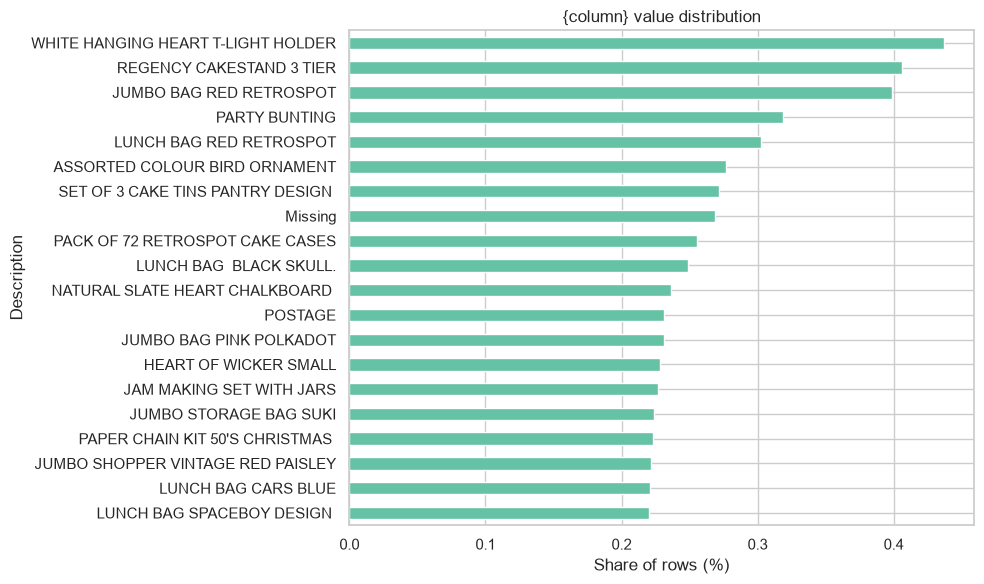

In [30]:
column = "Description"
percentages = df[column].astype("string").fillna("Missing").value_counts(normalize=True).mul(100)
display(percentages.head(20).rename("Percentage (%)").round(2))
ax = percentages.head(20).sort_values().plot.barh(figsize=(10, 6))
ax.set(title=f"{{column}} value distribution", xlabel="Share of rows (%)", ylabel=column)
plt.tight_layout()
plt.show()

## CustomerID

CustomerID
Missing    24.93
17841.0     1.47
14911.0     1.09
14096.0     0.95
12748.0     0.86
14606.0     0.51
15311.0     0.46
14646.0     0.38
13089.0     0.34
13263.0     0.31
14298.0      0.3
15039.0     0.28
14156.0     0.26
18118.0     0.24
14159.0     0.22
14796.0     0.21
15005.0     0.21
16033.0     0.21
14056.0     0.21
14769.0      0.2
Name: Percentage (%), dtype: Float64

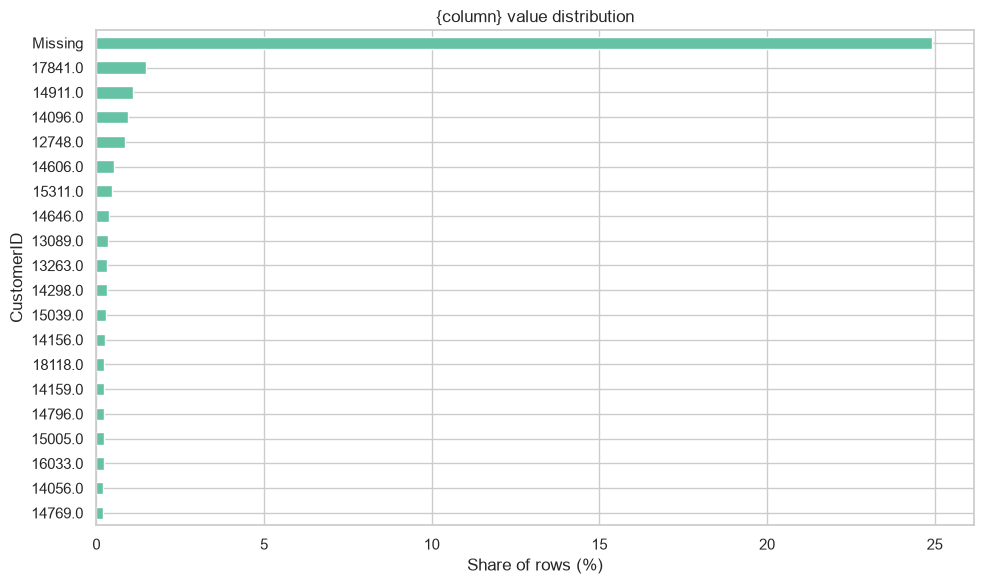

In [31]:
column = "CustomerID"
percentages = df[column].astype("string").fillna("Missing").value_counts(normalize=True).mul(100)
display(percentages.head(20).rename("Percentage (%)").round(2))
ax = percentages.head(20).sort_values().plot.barh(figsize=(10, 6))
ax.set(title=f"{{column}} value distribution", xlabel="Share of rows (%)", ylabel=column)
plt.tight_layout()
plt.show()

## Country

Country
United Kingdom          91.43
Germany                  1.75
France                   1.58
EIRE                     1.51
Spain                    0.47
Netherlands              0.44
Belgium                  0.38
Switzerland              0.37
Portugal                 0.28
Australia                0.23
Norway                    0.2
Italy                    0.15
Channel Islands          0.14
Finland                  0.13
Cyprus                   0.11
Sweden                   0.09
Unspecified              0.08
Austria                  0.07
Denmark                  0.07
Japan                    0.07
Poland                   0.06
Israel                   0.05
USA                      0.05
Hong Kong                0.05
Singapore                0.04
Iceland                  0.03
Canada                   0.03
Greece                   0.03
Malta                    0.02
United Arab Emirates     0.01
European Community       0.01
RSA                      0.01
Lebanon                  0.01
Li

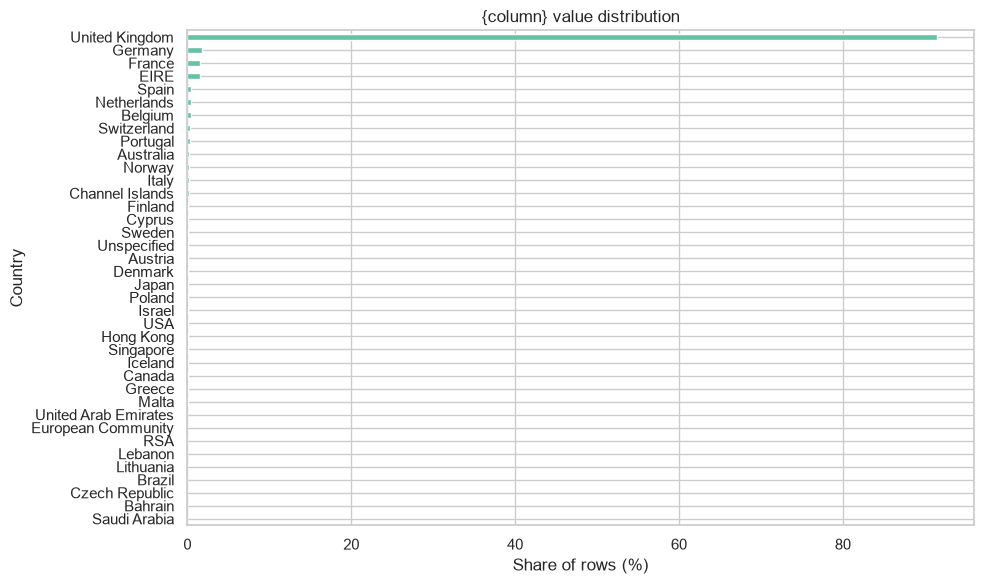

In [32]:
column = "Country"
percentages = df[column].astype("string").fillna("Missing").value_counts(normalize=True).mul(100)
display(percentages.head(100).rename("Percentage (%)").round(2))
ax = percentages.head(100).sort_values().plot.barh(figsize=(10, 6))
ax.set(title=f"{{column}} value distribution", xlabel="Share of rows (%)", ylabel=column)
plt.tight_layout()
plt.show()

## Quantity

Skewness: -0.264
Kurtosis (Fisher): 119769.160


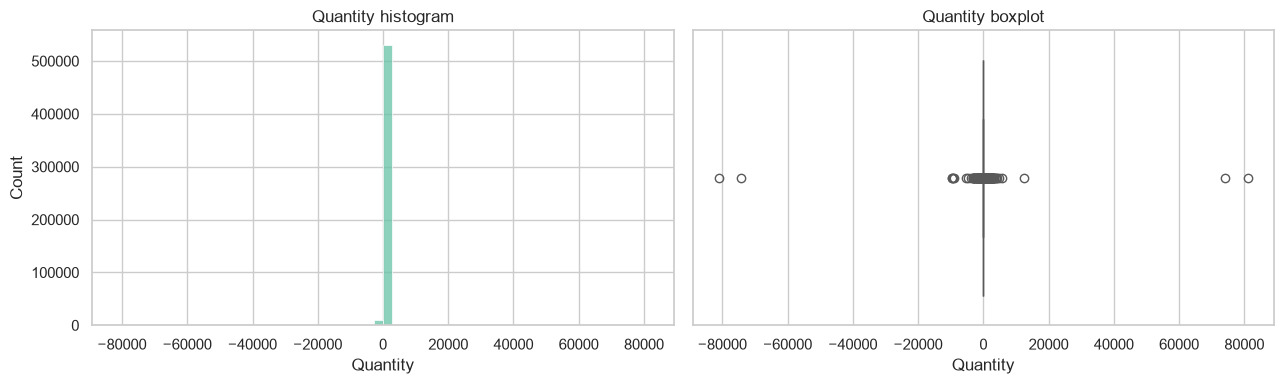

In [33]:
values = df["Quantity"].dropna()
print(f"Skewness: {values.skew():.3f}")
print(f"Kurtosis (Fisher): {values.kurtosis():.3f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(values, bins=60, ax=axes[0])
axes[0].set(title="Quantity histogram", xlabel="Quantity")
sns.boxplot(x=values, ax=axes[1])
axes[1].set(title="Quantity boxplot", xlabel="Quantity")
plt.tight_layout()
plt.show()

## InvoiceDate

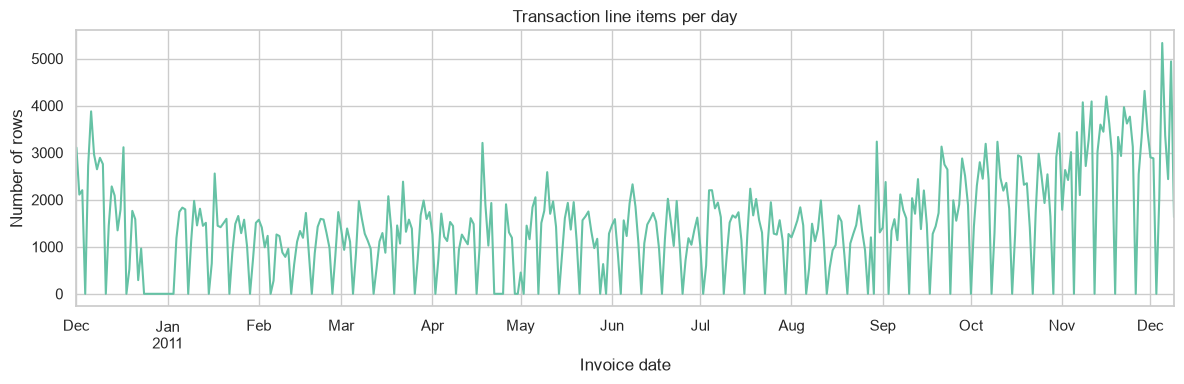

Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [34]:
daily_lines = df.set_index("InvoiceDate").resample("D").size()
ax = daily_lines.plot(figsize=(12, 4))
ax.set(title="Transaction line items per day", xlabel="Invoice date", ylabel="Number of rows")
plt.tight_layout()
plt.show()
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

## UnitPrice

Skewness: 186.507
Kurtosis (Fisher): 59005.719


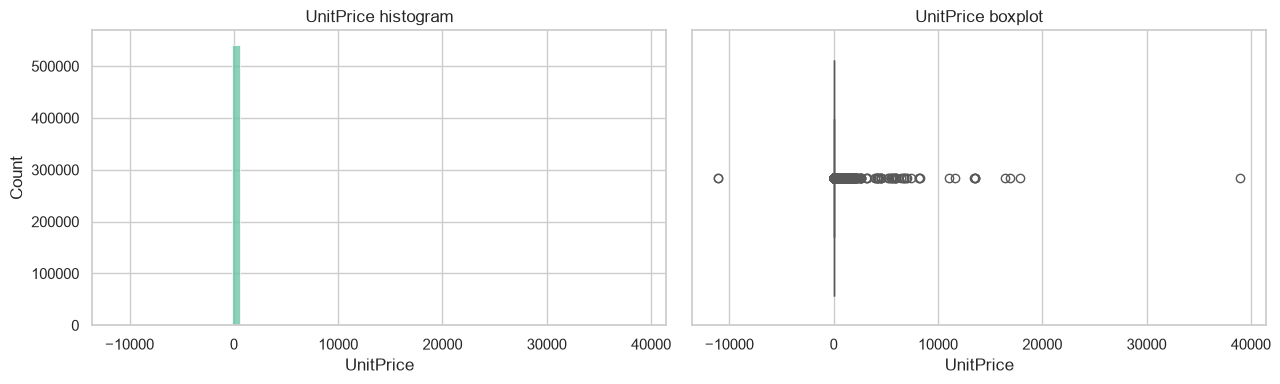

In [35]:
values = df["UnitPrice"].dropna()
print(f"Skewness: {values.skew():.3f}")
print(f"Kurtosis (Fisher): {values.kurtosis():.3f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(values, bins=60, ax=axes[0])
axes[0].set(title="UnitPrice histogram", xlabel="UnitPrice")
sns.boxplot(x=values, ax=axes[1])
axes[1].set(title="UnitPrice boxplot", xlabel="UnitPrice")
plt.tight_layout()
plt.show()

# Correlation Analysis

Quantity and UnitPrice are transaction-level numeric measures. InvoiceNo, StockCode, CustomerID, and Country are categorical or identifiers; InvoiceDate is treated as time. Correlation indicates association, not causation.

## Numeric versus numeric: Quantity and UnitPrice

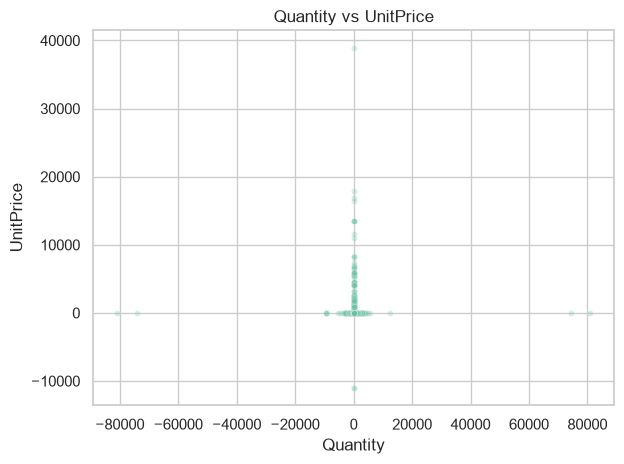

Pearson r=-0.0012, p-value=0.3633
Spearman rho=-0.3854, p-value=0


In [36]:
pair = ["Quantity", "UnitPrice"]
data = df[pair].dropna()
sns.scatterplot(data=data, x=pair[0], y=pair[1], alpha=0.25, s=18)
plt.title("Quantity vs UnitPrice")
plt.tight_layout()
plt.show()
pearson_r, pearson_p = stats.pearsonr(data[pair[0]], data[pair[1]])
spearman_r, spearman_p = stats.spearmanr(data[pair[0]], data[pair[1]])
print(f"Pearson r={pearson_r:.4f}, p-value={pearson_p:.4g}")
print(f"Spearman rho={spearman_r:.4f}, p-value={spearman_p:.4g}")

## Numeric versus categorical: within-class percentages

Numeric values are grouped into quantile bins. Charts show the percentage distribution of the bins within each categorical class. For readability, only the 10 most frequent classes are shown and the rest are grouped as Other. Identifiers are included for inspection, not interpretation as explanatory groups.


Quantity quantile percentages within InvoiceNo classes


Quantity,"(-80995.001, 1.0]","(1.0, 2.0]","(12.0, 80995.0]","(2.0, 5.0]","(5.0, 12.0]"
InvoiceNo,,,,,
537434,51.0,19.6,3.0,18.7,7.9
538071,53.1,19.9,1.5,17.9,7.5
558475,40.1,17.3,12.8,17.4,12.3
573585,40.2,16.8,6.3,22.9,13.8
579777,49.6,22.6,1.9,20.2,5.7
580729,48.7,21.5,4.0,17.8,8.0
580730,52.9,20.7,3.0,18.3,5.1
581217,50.6,19.1,2.5,19.2,8.6
581219,46.9,22.2,2.1,19.5,9.3


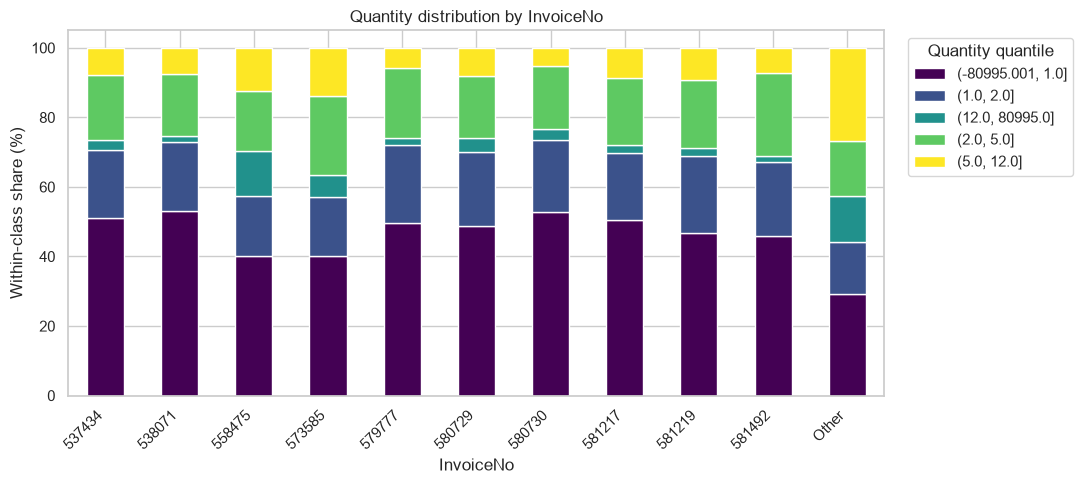


Quantity quantile percentages within StockCode classes


Quantity,"(-80995.001, 1.0]","(1.0, 2.0]","(12.0, 80995.0]","(2.0, 5.0]","(5.0, 12.0]"
StockCode,,,,,
20725,19.3,11.6,16.2,11.8,41.1
20727,20.8,14.9,11.8,15.5,37.0
21212,19.5,8.6,53.9,11.2,6.8
22197,8.6,9.2,36.2,15.0,30.9
22423,35.8,21.3,15.4,17.7,9.8
22720,26.7,13.4,4.7,43.2,12.1
47566,14.0,11.4,13.7,38.3,22.6
84879,2.4,0.9,49.5,3.9,43.4
85099B,14.4,10.4,23.6,13.4,38.3


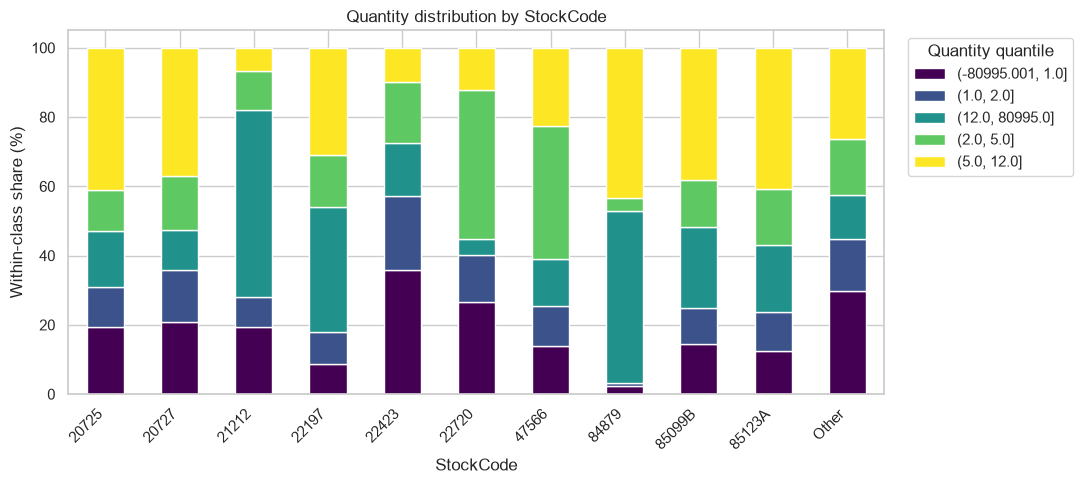


Quantity quantile percentages within Description classes


Quantity,"(-80995.001, 1.0]","(1.0, 2.0]","(12.0, 80995.0]","(2.0, 5.0]","(5.0, 12.0]"
Description,,,,,
ASSORTED COLOUR BIRD ORNAMENT,2.3,0.9,49.5,3.9,43.4
JUMBO BAG RED RETROSPOT,14.4,10.4,23.6,13.4,38.3
LUNCH BAG BLACK SKULL.,20.8,14.9,11.8,15.5,37.0
LUNCH BAG RED RETROSPOT,19.4,11.6,16.2,11.8,41.1
Missing,68.0,4.5,15.1,5.7,6.7
Other,29.5,15.2,12.7,16.1,26.4
PACK OF 72 RETROSPOT CAKE CASES,19.5,8.6,53.9,11.2,6.8
PARTY BUNTING,14.0,11.4,13.7,38.3,22.6
REGENCY CAKESTAND 3 TIER,35.7,21.4,15.4,17.7,9.8


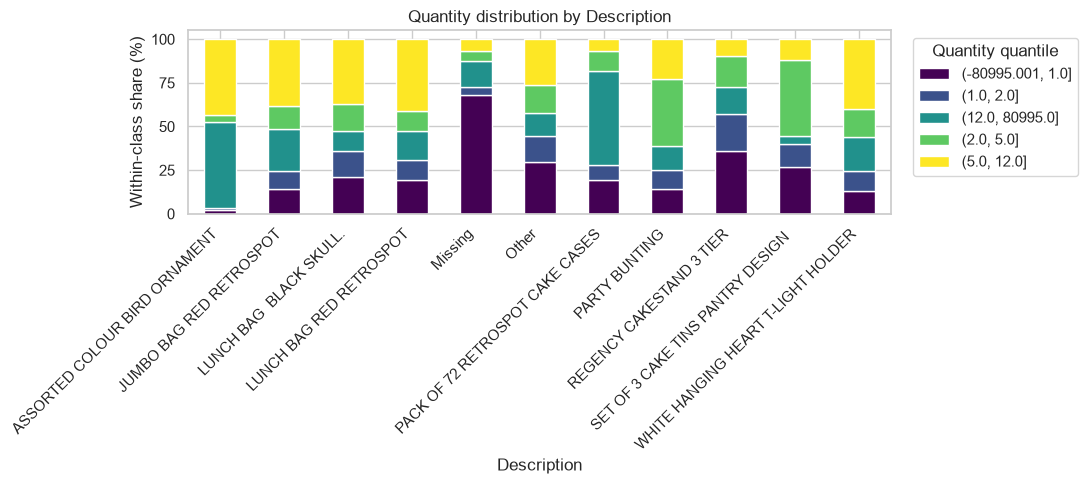


Quantity quantile percentages within CustomerID classes


Quantity,"(-80995.001, 1.0]","(1.0, 2.0]","(12.0, 80995.0]","(2.0, 5.0]","(5.0, 12.0]"
CustomerID,,,,,
12748.0,50.3,18.2,7.3,12.3,11.9
13089.0,2.5,2.1,31.0,7.5,56.9
13263.0,36.9,35.7,2.3,19.6,5.5
14096.0,46.5,18.9,3.1,21.1,10.4
14606.0,70.4,15.2,1.8,8.1,4.5
14646.0,7.1,1.0,83.6,1.6,6.7
14911.0,6.6,8.7,21.0,14.3,49.4
15311.0,29.2,25.5,18.1,15.7,11.4
17841.0,55.6,20.2,2.7,14.5,7.2


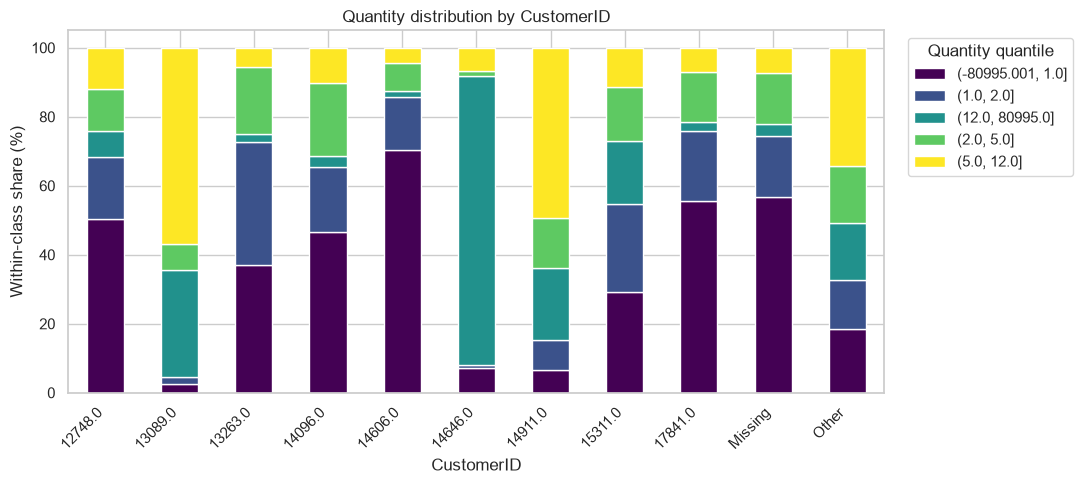


Quantity quantile percentages within Country classes


Quantity,"(-80995.001, 1.0]","(1.0, 2.0]","(12.0, 80995.0]","(2.0, 5.0]","(5.0, 12.0]"
Country,,,,,
Australia,10.0,2.9,57.5,7.6,22.0
Belgium,4.5,7.6,17.0,16.2,54.6
EIRE,6.5,8.8,23.8,14.3,46.5
France,6.0,6.9,21.0,13.1,53.0
Germany,7.6,5.8,20.7,12.7,53.2
Netherlands,7.4,1.9,76.3,2.5,11.9
Other,9.4,7.6,27.0,12.4,43.5
Portugal,8.9,10.6,18.4,16.7,45.4
Spain,12.2,12.3,15.0,16.3,44.1


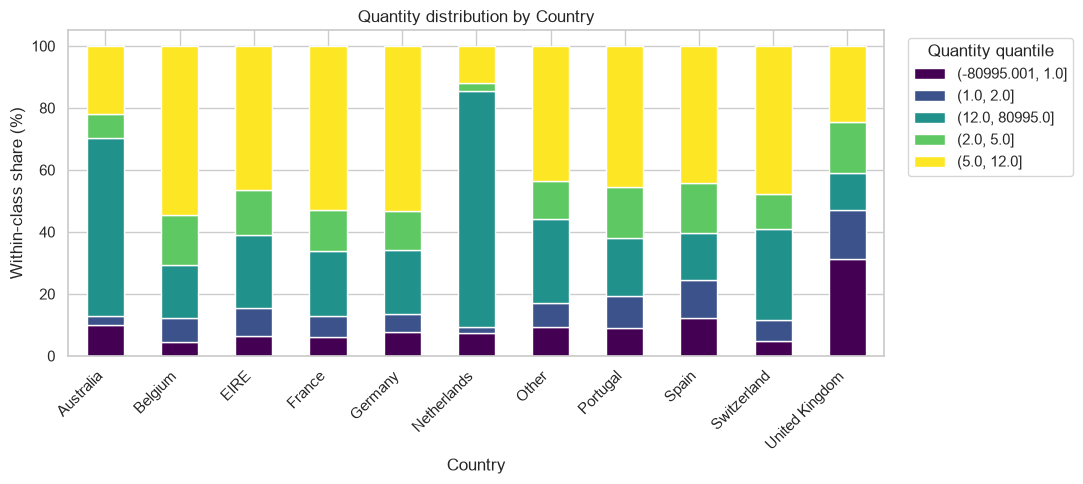


UnitPrice quantile percentages within InvoiceNo classes


UnitPrice,"(-11062.061, 0.85]","(0.85, 1.65]","(1.65, 2.55]","(2.55, 4.95]","(4.95, 38970.0]"
InvoiceNo,,,,,
537434,9.8,2.5,31.0,23.7,33.0
538071,11.2,2.3,31.0,24.7,30.8
558475,25.2,19.7,18.0,22.0,15.0
573585,12.8,14.8,18.0,24.5,29.8
579777,12.4,15.4,18.9,26.5,26.8
580729,11.5,16.4,17.9,26.9,27.3
580730,13.7,13.9,17.4,26.6,28.4
581217,14.1,16.7,18.5,25.6,25.1
581219,14.3,15.5,18.2,25.2,26.8


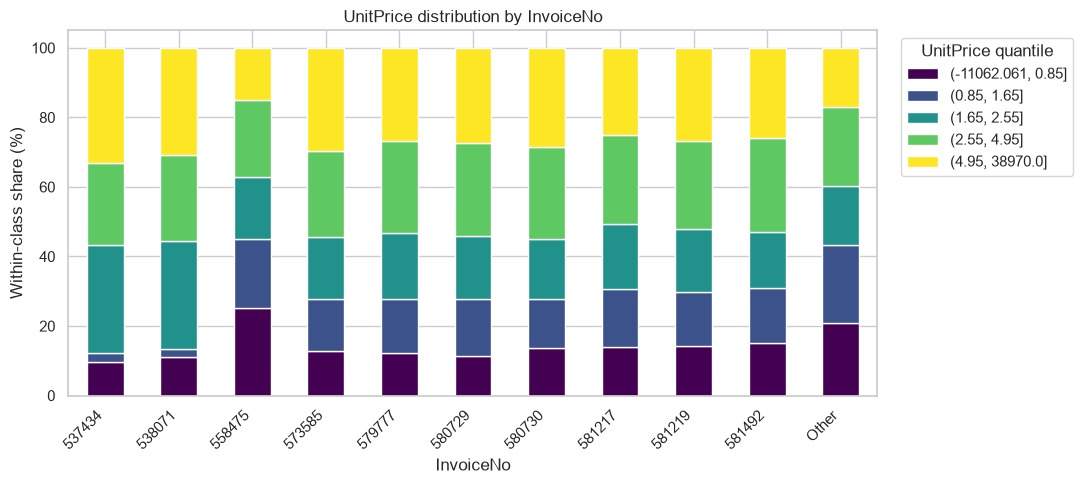


UnitPrice quantile percentages within StockCode classes


UnitPrice,"(-11062.061, 0.85]","(0.85, 1.65]","(1.65, 2.55]","(2.55, 4.95]","(4.95, 38970.0]"
StockCode,,,,,
20725,0.0,83.1,0.0,10.9,6.0
20727,0.0,84.4,0.0,9.0,6.5
21212,78.9,14.8,5.8,0.0,0.4
22197,76.4,18.7,4.9,0.0,0.0
22423,0.2,0.0,0.0,0.1,99.7
22720,0.3,0.0,0.0,84.8,14.9
47566,0.1,0.0,0.0,83.0,17.0
84879,0.1,4.1,92.9,2.9,0.0
85099B,0.1,3.3,74.8,21.8,0.0


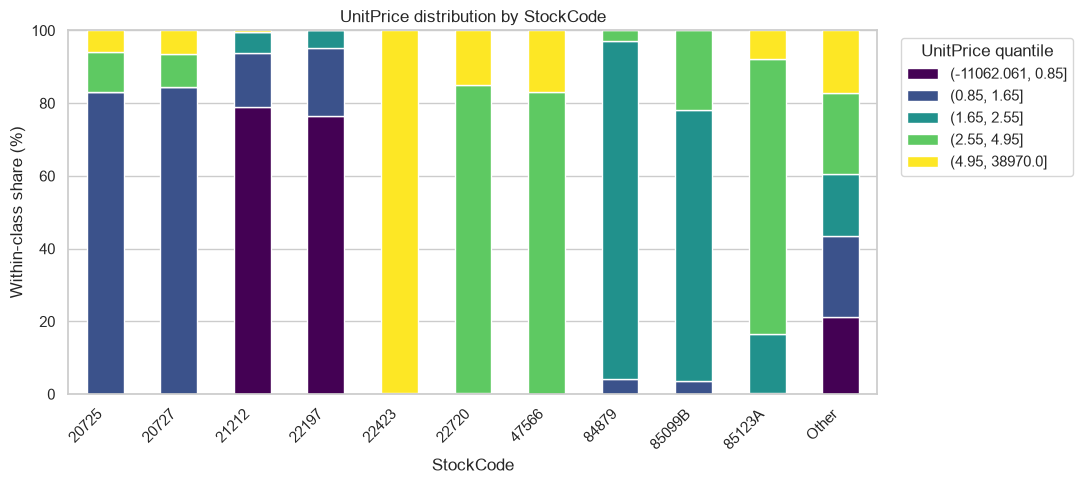


UnitPrice quantile percentages within Description classes


UnitPrice,"(-11062.061, 0.85]","(0.85, 1.65]","(1.65, 2.55]","(2.55, 4.95]","(4.95, 38970.0]"
Description,,,,,
ASSORTED COLOUR BIRD ORNAMENT,0.0,4.1,92.9,2.9,0.0
JUMBO BAG RED RETROSPOT,0.1,3.3,74.8,21.8,0.0
LUNCH BAG BLACK SKULL.,0.0,84.4,0.0,9.0,6.5
LUNCH BAG RED RETROSPOT,0.0,83.1,0.0,10.9,6.0
Missing,100.0,0.0,0.0,0.0,0.0
Other,21.1,22.3,17.1,22.5,17.1
PACK OF 72 RETROSPOT CAKE CASES,78.9,14.8,5.8,0.0,0.4
PARTY BUNTING,0.1,0.0,0.0,83.0,17.0
REGENCY CAKESTAND 3 TIER,0.1,0.0,0.0,0.1,99.8


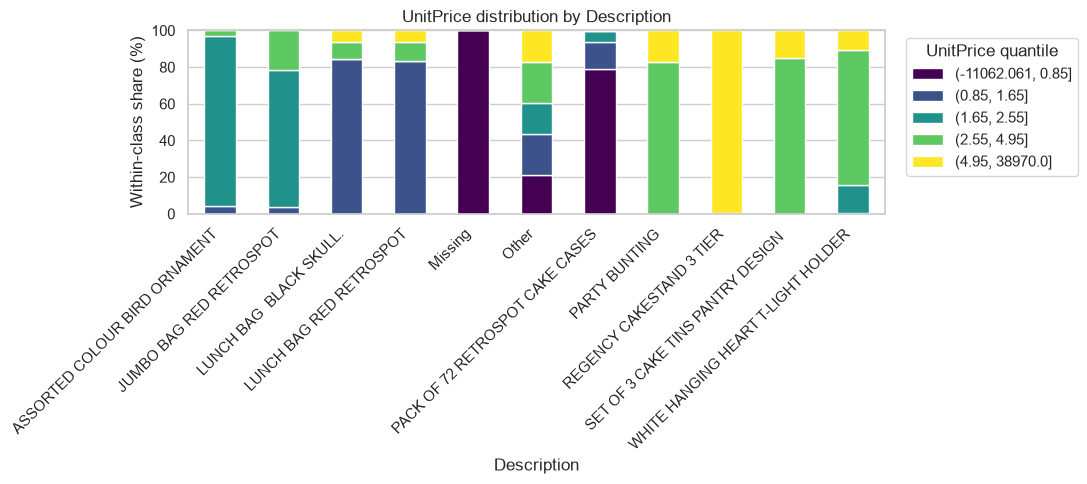


UnitPrice quantile percentages within CustomerID classes


UnitPrice,"(-11062.061, 0.85]","(0.85, 1.65]","(1.65, 2.55]","(2.55, 4.95]","(4.95, 38970.0]"
CustomerID,,,,,
12748.0,29.3,26.8,16.3,18.5,9.0
13089.0,24.2,27.4,14.5,20.5,13.4
13263.0,24.0,31.0,15.6,23.1,6.3
14096.0,11.1,17.5,20.9,22.7,27.7
14606.0,23.4,29.2,14.9,19.5,13.1
14646.0,26.4,33.9,18.5,13.0,8.2
14911.0,22.5,20.5,12.9,25.1,19.0
15311.0,17.2,32.6,20.3,17.2,12.7
17841.0,24.8,30.1,16.2,19.0,9.9


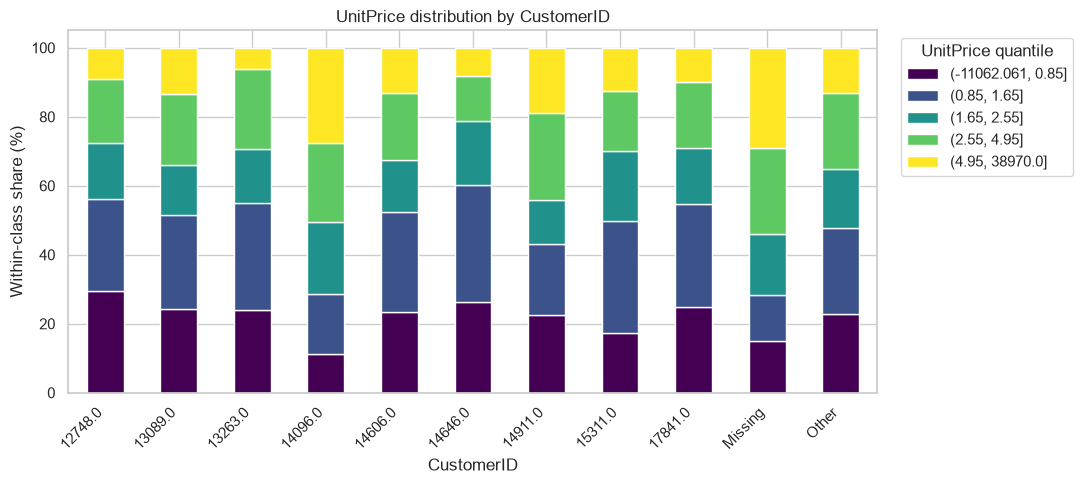


UnitPrice quantile percentages within Country classes


UnitPrice,"(-11062.061, 0.85]","(0.85, 1.65]","(1.65, 2.55]","(2.55, 4.95]","(4.95, 38970.0]"
Country,,,,,
Australia,19.9,28.4,14.8,24.5,12.5
Belgium,24.0,19.3,16.5,23.5,16.6
EIRE,21.2,21.5,13.3,24.9,19.0
France,23.9,25.0,18.2,19.0,13.9
Germany,22.9,24.8,16.0,21.1,15.3
Netherlands,27.0,32.4,17.8,13.5,9.4
Other,21.0,22.3,15.1,24.1,17.5
Portugal,22.3,28.5,17.2,20.9,11.1
Spain,19.7,25.0,13.3,24.2,17.8


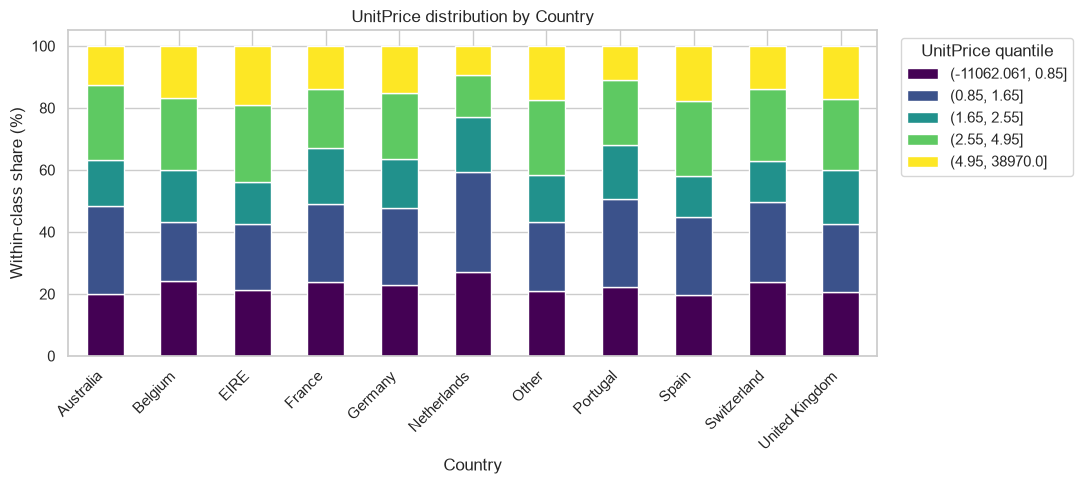

In [37]:
for numeric_column in ["Quantity", "UnitPrice"]:
    numeric_bins = pd.qcut(df[numeric_column], q=5, duplicates="drop").astype("string").fillna("Missing")
    for categorical_column in ["InvoiceNo", "StockCode", "Description", "CustomerID", "Country"]:
        category = df[categorical_column].astype("string").fillna("Missing")
        top_classes = category.value_counts().head(10).index
        category = category.where(category.isin(top_classes), "Other")
        percentages = pd.crosstab(category, numeric_bins, normalize="index").mul(100)
        print(f"\n{numeric_column} quantile percentages within {categorical_column} classes")
        display(percentages.round(1))
        ax = percentages.plot.bar(stacked=True, figsize=(11, 5), colormap="viridis")
        ax.set(title=f"{numeric_column} distribution by {categorical_column}",
               xlabel=categorical_column, ylabel="Within-class share (%)")
        ax.legend(title=f"{numeric_column} quantile", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

# Collinearity Analysis

Assess collinearity among numeric variables that may be used together as model features. Identifiers are excluded. Pairwise correlation and VIF are diagnostics, not automatic reasons to remove a variable.

## Quantity and UnitPrice

,Quantity,UnitPrice
Quantity,1.000000,-0.001235
UnitPrice,-0.001235,1.000000


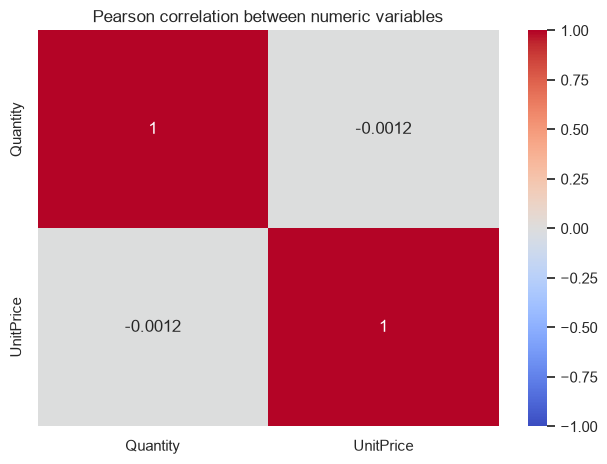

,Feature,VIF
0,Quantity,1.000002
1,UnitPrice,1.000002


In [38]:
features = df[["Quantity", "UnitPrice"]].replace([np.inf, -np.inf], np.nan).dropna()
correlation = features.corr()
display(correlation)
sns.heatmap(correlation, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Pearson correlation between numeric variables")
plt.tight_layout()
plt.show()

# Calculate VIF by regressing each variable on the remaining variables.
vif_results = []
for feature in features.columns:
    target = features[feature].to_numpy(dtype=float)
    others = features.drop(columns=feature).to_numpy(dtype=float)
    design = np.column_stack([np.ones(len(others)), others])
    fitted = design @ np.linalg.lstsq(design, target, rcond=None)[0]
    total = np.sum((target - target.mean()) ** 2)
    r_squared = 1 - np.sum((target - fitted) ** 2) / total if total else 1.0
    vif = np.inf if np.isclose(1 - r_squared, 0) else 1 / (1 - r_squared)
    vif_results.append({"Feature": feature, "VIF": vif})
display(pd.DataFrame(vif_results))

# Questions for Domain Analysis

The following cells answer each question using the transaction data.

## 1. Product and country sales contribution

Which products and countries contribute the largest shares of transaction lines and sales, and how concentrated are those contributions?

,,Lines,Sales,SalesSharePct,LineSharePct
StockCode,Description,,,,
DOT,DOTCOM POSTAGE,706,206248.77,1.93,0.13
22423,REGENCY CAKESTAND 3 TIER,2017,174484.74,1.64,0.38
23843,"PAPER CRAFT , LITTLE BIRDIE",1,168469.60,1.58,0.00
85123A,WHITE HANGING HEART T-LIGHT HOLDER,2256,104340.29,0.98,0.43
47566,PARTY BUNTING,1706,99504.33,0.93,0.32
85099B,JUMBO BAG RED RETROSPOT,2112,94340.05,0.88,0.40
23166,MEDIUM CERAMIC TOP STORAGE JAR,250,81700.92,0.77,0.05
M,Manual,321,78110.27,0.73,0.06
POST,POSTAGE,1126,78101.88,0.73,0.21


,Lines,Sales,SalesSharePct,LineSharePct
Country,,,,
United Kingdom,485123,9025222.08,84.61,91.51
Netherlands,2359,285446.34,2.68,0.45
EIRE,7890,283453.96,2.66,1.49
Germany,9040,228867.14,2.15,1.71
France,8407,209715.11,1.97,1.59
Australia,1182,138521.31,1.30,0.22
Spain,2484,61577.11,0.58,0.47
Switzerland,1966,57089.90,0.54,0.37
Belgium,2031,41196.34,0.39,0.38


Top 10 products' sales share: 10.8%
Top 10 countries' sales share: 97.2%


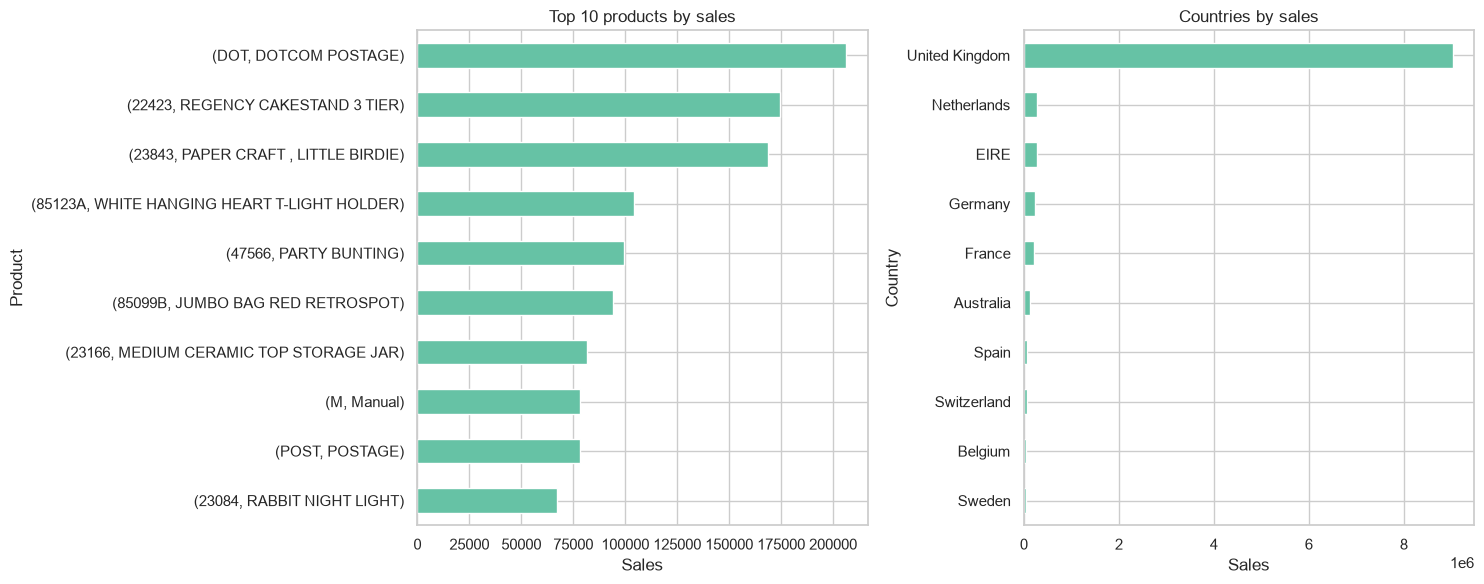

In [39]:
cancelled = df["InvoiceNo"].astype("string").str.startswith("C", na=False)
sales = df.loc[~cancelled & (df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
sales["Sales"] = sales["Quantity"] * sales["UnitPrice"]

def contribution(data, keys):
    result = data.groupby(keys, dropna=False).agg(
        Lines=("InvoiceNo", "size"), Sales=("Sales", "sum")
    ).sort_values("Sales", ascending=False)
    result["SalesSharePct"] = result["Sales"] / result["Sales"].sum() * 100
    result["LineSharePct"] = result["Lines"] / result["Lines"].sum() * 100
    return result

product_sales = contribution(sales, ["StockCode", "Description"])
country_sales = contribution(sales, ["Country"])
display(product_sales.head(10).round(2))
display(country_sales.round(2))
print(f"Top 10 products' sales share: {product_sales.head(10)['SalesSharePct'].sum():.1f}%")
print(f"Top 10 countries' sales share: {country_sales.head(10)['SalesSharePct'].sum():.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
product_sales.head(10)["Sales"].sort_values().plot.barh(ax=axes[0])
axes[0].set(title="Top 10 products by sales", xlabel="Sales", ylabel="Product")
country_sales.head(10)["Sales"].sort_values().plot.barh(ax=axes[1])
axes[1].set(title="Countries by sales", xlabel="Sales", ylabel="Country")
plt.tight_layout()
plt.show()

## 2. Product price and quantity relationship

How do quantities and unit prices vary across products, and are lower-priced items typically purchased in larger quantities?

,,MedianPrice,MedianQuantity,MeanQuantity,Lines
StockCode,Description,,,,
16045,POPART WOODEN PENCILS ASST,0.04,100.0,128.99,69
16216,LETTER SHAPE PENCIL SHARPENER,0.06,15.0,74.07,45
16218,CARTOON PENCIL SHARPENERS,0.06,80.0,59.70,64
16259,PIECE OF CAMO STATIONERY SET,0.08,108.0,109.03,31
17136A,BLUE STONES ON WIRE FOR CANDLE,0.08,24.0,20.20,20
17038,PORCELAIN BUDAH INCENSE HOLDER,0.10,4.0,44.85,34
16161G,WRAP BAD HAIR DAY,0.10,25.0,31.82,22
21402,RED EGG SPOON,0.12,6.0,14.88,92
16054,POPART RECT PENCIL SHARPENER ASST,0.12,36.0,35.33,33


,,MedianPrice,MedianQuantity,MeanQuantity,Lines
StockCode,Description,,,,
16049,TEATIME GEL PENS ASST,0.12,144.0,100.80,5
16259,PIECE OF CAMO STATIONERY SET,0.08,108.0,109.03,31
16045,POPART WOODEN PENCILS ASST,0.04,100.0,128.99,69
16218,CARTOON PENCIL SHARPENERS,0.06,80.0,59.70,64
17084R,ASSORTED INCENSE PACK,0.21,72.0,149.33,27
21395,BLUE POLKADOT BEAKER,0.39,48.0,31.25,91
23327,HANGING CLEAR MINI BOTTLE,0.63,48.0,41.29,42
23326,HANGING MINI COLOURED BOTTLES,0.63,48.0,44.71,77
22741,FUNKY DIVA PEN,0.85,48.0,36.53,234


Product-level Spearman correlation: rho=-0.547, p-value=1.182e-280
Products included (at least 5 lines): 3,611


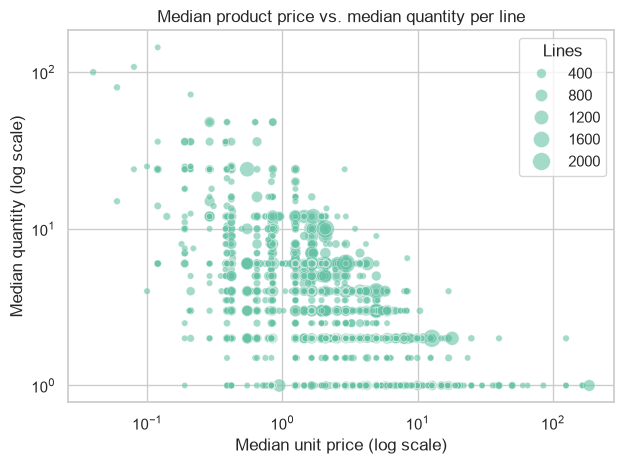

In [40]:
product_behavior = (
    sales.groupby(["StockCode", "Description"], dropna=False)
    .agg(MedianPrice=("UnitPrice", "median"),
         MedianQuantity=("Quantity", "median"),
         MeanQuantity=("Quantity", "mean"),
         Lines=("InvoiceNo", "size"))
    .query("Lines >= 5")
)
display(product_behavior.sort_values("MedianPrice").head(10).round(2))
display(product_behavior.sort_values("MedianQuantity", ascending=False).head(10).round(2))
rho, p_value = stats.spearmanr(product_behavior["MedianPrice"], product_behavior["MedianQuantity"])
print(f"Product-level Spearman correlation: rho={rho:.3f}, p-value={p_value:.4g}")
print(f"Products included (at least 5 lines): {len(product_behavior):,}")

sns.scatterplot(data=product_behavior, x="MedianPrice", y="MedianQuantity",
                size="Lines", sizes=(20, 180), alpha=0.6)
plt.xscale("log")
plt.yscale("log")
plt.title("Median product price vs. median quantity per line")
plt.xlabel("Median unit price (log scale)")
plt.ylabel("Median quantity (log scale)")
plt.tight_layout()
plt.show()

## 3. Cancellations, returns, and invalid values

What share of transaction lines represent cancellations, returns, or non-positive prices or quantities, and how do those patterns vary by product or country?

,LineCount,PercentOfAllLines
Cancellation invoice,9288,1.71
Negative quantity (return/adjustment),10624,1.96
Non-positive quantity,10624,1.96
Non-positive unit price,2517,0.46


Cancellation and negative-quantity lines overlap: 9288


,Lines,CancellationPct,NegativeQuantityPct
Country,,,
USA,291,38.49,38.49
Czech Republic,30,16.67,16.67
Malta,127,11.81,11.81
Japan,358,10.34,10.34
Australia,1259,5.88,5.88
Italy,803,5.6,5.60
Germany,9495,4.77,4.77
EIRE,8196,3.68,3.68
Poland,341,3.23,3.23


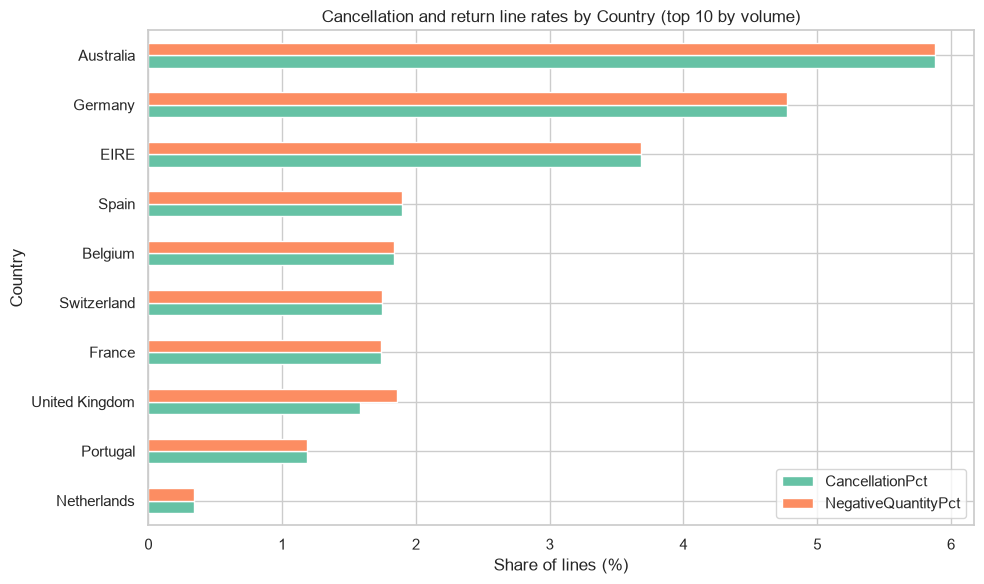

,Lines,CancellationPct,NegativeQuantityPct
Product,,,
D - Discount,77,100.0,100.00
S - SAMPLES,63,96.83,96.83
AMAZONFEE - AMAZON FEE,34,94.12,94.12
BANK CHARGES - Bank Charges,37,67.57,67.57
M - Manual,571,42.73,42.73
23064 - CINDERELLA CHANDELIER,33,30.3,30.30
23462 - ROCOCO WALL MIRROR WHITE,57,21.05,21.05
22461 - SAVOY ART DECO CLOCK,66,19.7,19.70
"85159B - WHITE TEA,COFFEE,SUGAR JARS",72,18.06,18.06


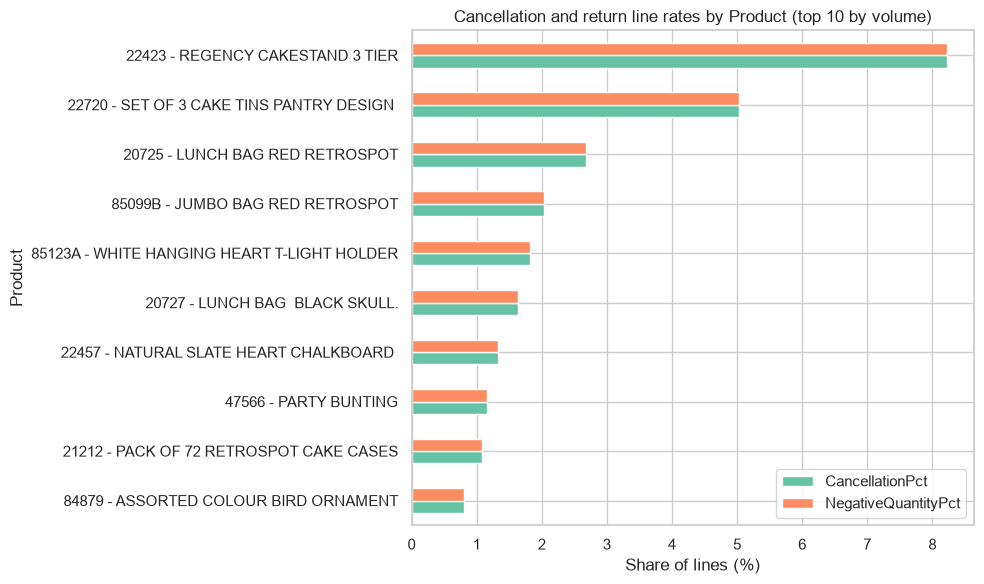

In [41]:
cancelled = df["InvoiceNo"].astype("string").str.startswith("C", na=False)
negative_quantity = df["Quantity"] < 0
flags = pd.DataFrame({
    "Cancellation invoice": cancelled,
    "Negative quantity (return/adjustment)": negative_quantity,
    "Non-positive quantity": df["Quantity"] <= 0,
    "Non-positive unit price": df["UnitPrice"] <= 0,
})
display(pd.DataFrame({"LineCount": flags.sum(),
                      "PercentOfAllLines": (flags.mean() * 100).round(2)}))
print("Cancellation and negative-quantity lines overlap:",
      int((cancelled & negative_quantity).sum()))

issues = df.copy()
issues["CancellationFlag"] = cancelled
issues["NegativeQuantityFlag"] = negative_quantity
issues["Product"] = (issues["StockCode"].astype("string").fillna("Missing")
                     + " - " + issues["Description"].astype("string").fillna("Missing"))

def issue_rates(data, key):
    rates = data.groupby(key, dropna=False).agg(
        Lines=("InvoiceNo", "size"),
        CancellationPct=("CancellationFlag", "mean"),
        NegativeQuantityPct=("NegativeQuantityFlag", "mean"))
    rates[["CancellationPct", "NegativeQuantityPct"]] *= 100
    return rates.query("Lines >= 30")

for key in ["Country", "Product"]:
    rates = issue_rates(issues, key)
    display(rates.sort_values("CancellationPct", ascending=False).head(10).round(2))
    top_volume = rates.sort_values("Lines", ascending=False).head(10)
    ax = top_volume[["CancellationPct", "NegativeQuantityPct"]].sort_values(
        "CancellationPct").plot.barh(figsize=(10, 6))
    ax.set(title=f"Cancellation and return line rates by {key} (top 10 by volume)",
           xlabel="Share of lines (%)", ylabel=key)
    plt.tight_layout()
    plt.show()